In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

# Case 1: simple function with one main activated mode
$ pressure = cos(X + x_{phase}) * cos(Y) * cos(Z + z_{phase})$


In [2]:
def plot_energy_per_mode(data, kx, ky, kz, bins_count):
    wavevector = np.sqrt(kx[:, None, None]**2 + ky[None, :, None]**2 + kz[None, None, :]**2)
    energy_per_mode = abs(data)**2
    bins = np.linspace(0, min(abs(kx).max(), abs(ky).max(), abs(kz).max()), bins_count)
    centers = np.concatenate(([bins[0] - (bins[1] - bins[0]) / 2.0], ((bins[1:] - bins[:-1]) / 2.0 + bins[:-1]), [bins[-1] + (bins[-1] - bins[-2]) / 2]))
    mode_bin = np.digitize(wavevector.ravel(), bins)
    energy_per_scale = np.bincount(mode_bin, weights=energy_per_mode.ravel(), minlength=len(bins)+1)
    plt.title("Energy per wavevector norm")
    plt.bar(centers, energy_per_scale, width=bins[1] - bins[0])
    plt.yscale("log")
    plt.show()

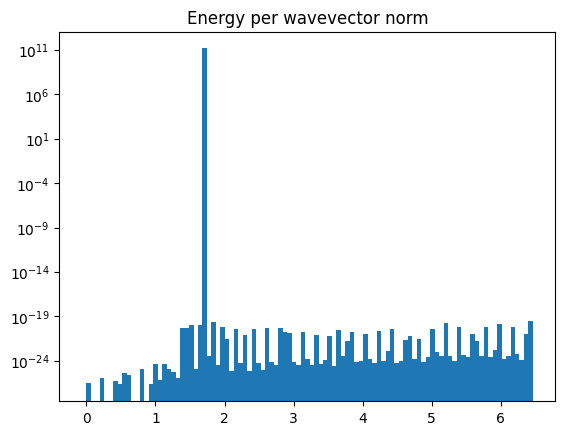

In [3]:
nx = 64
x_period = 2
Lx = 2*np.pi * x_period
ny = 64
Ly = np.pi
nz = 64
z_period = 5
Lz = 2*np.pi * z_period
x = np.linspace(0, Lx, nx, endpoint=False)
y = np.linspace(0, Ly, ny)
z = np.linspace(0, Lz, nz, endpoint=False)
x_phase = 0.4
z_phase = 1.7
X, Y, Z = np.ix_(x, y, z)
p = np.cos(X + x_phase) * np.cos(Y) * np.cos(Z + z_phase)
rhs = -3 * p
dx = Lx / nx
dy = Ly / (ny - 1)
dz = Lz / nz
kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
ky = np.pi * np.arange(ny) / Ly
kz = 2 * np.pi * np.fft.fftfreq(nz, dz)
rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)
plot_energy_per_mode(rhshat, kx, ky, kz, 100)

In [4]:
# raw K2 on collocated grid
def collocated_pressure_1(rhs, nx, ny, nz, Lx, Ly, Lz):
    dx = Lx / nx
    dy = Ly / (ny - 1)
    dz = Lz / nz
    kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
    ky = np.pi * np.arange(ny) / Ly
    kz = 2 * np.pi * np.fft.fftfreq(nz, dz)
    rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
    rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)
    K2 = -(kx[:, None, None]**2 + ky[None, :, None]**2 + kz[None, None, :]**2)
    K2[0, 0, 0] = 1.0
    phat = rhshat / K2
    phat[0, 0, 0] = 0.0
    interxz = scp.fft.idct(phat, type=1, axis=1) 
    p_solver = np.fft.ifftn(interxz, axes=(0, 2))
    return p_solver.real

In [60]:
# modified wavenumbers on collocated grid
def collocated_pressure_modified_wavenumbers(rhs, nx, ny, nz, Lx, Ly, Lz):
    dx = Lx / nx
    dy = Ly / (ny - 1)
    dz = Lz / nz
    kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
    ky = np.pi * np.arange(ny) / Ly
    kz = 2 * np.pi * np.fft.fftfreq(nz, dz)
    rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
    rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)
    alpha = 1/3
    a = 14/9
    b = 1/9
    kprimex = (a * np.sin(kx * dx) + (b / 2) * np.sin(2 * kx * dx)) / (1 + 2 * alpha * np.cos(kx * dx)) * 1/dx
    kprimey = (a * np.sin(ky * dy) + (b / 2) * np.sin(2 * ky * dy)) / (1 + 2 * alpha * np.cos(ky * dy)) * 1/dy
    kprimez = (a * np.sin(kz * dz) + (b / 2) * np.sin(2 * kz * dz)) / (1 + 2 * alpha * np.cos(kz * dz)) * 1/dz
    K2 = -(kprimex[:, None, None]**2 + kprimey[None, :, None]**2 + kprimez[None, None, :]**2)
    tol = 1e-12 * np.abs(K2).max()
    singularity_mask = abs(K2) < tol
    K2[singularity_mask] = 1.0
    phat = rhshat / K2
    phat[singularity_mask] = 0.0
    interxz = scp.fft.idct(phat, type=1, axis=1) 
    p_solver = np.fft.ifftn(interxz, axes=(0, 2))
    return p_solver.real

In [5]:
def test_case1(solver):
    nx = 64
    x_period = 2
    Lx = 2*np.pi * x_period
    ny = 64
    Ly = np.pi
    nz = 64
    z_period = 5
    Lz = 2*np.pi * z_period
    x = np.linspace(0, Lx, nx, endpoint=False)
    y = np.linspace(0, Ly, ny)
    z = np.linspace(0, Lz, nz, endpoint=False)
    
    x_phase = 0.4
    z_phase = 1.7
    X, Y, Z = np.ix_(x, y, z)
    p = np.cos(X + x_phase) * np.cos(Y) * np.cos(Z + z_phase)
    rhs = -3 * p
    # run solver
    p_solver = solver(rhs, nx, ny, nz, Lx, Ly, Lz)
    p_ana = p - p.mean()
    p_num = p_solver.real - p_solver.real.mean()
    rel_rmse = np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))

    # plt visuals
    kslice = nz // 2
    ref = p_ana[:, :, kslice]
    num = p_num[:, :, kslice]
    
    vmin, vmax = ref.min(), ref.max()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    
    for a, f, t in zip(ax[:2], (ref, num), ("reference", "solver")):
        im = a.pcolormesh(x, y, f.T, vmin=vmin, vmax=vmax, shading="auto")
        a.set_title(t)
        a.set_xlabel("x"); a.set_ylabel("y")
    fig.colorbar(im, ax=ax[:2])
    
    err = ax[2].pcolormesh(x, y, (num - ref).T, shading="auto")
    ax[2].set_title("error")
    fig.colorbar(err, ax=ax[2])
    plt.show()
    print("rel rmse:", rel_rmse)

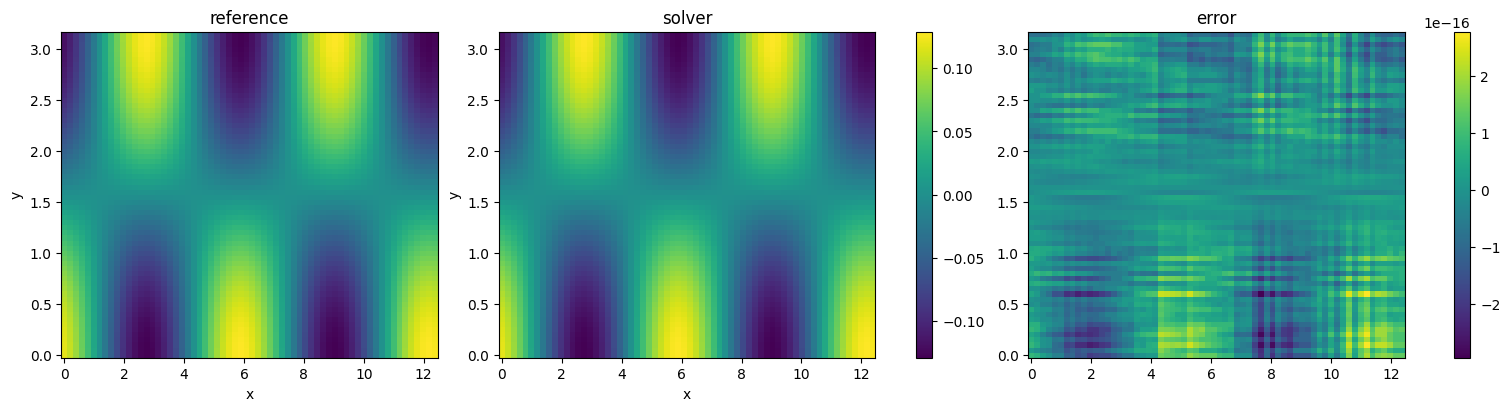

rel rmse: 7.565622815967334e-16


In [6]:
test_case1(collocated_pressure_1)

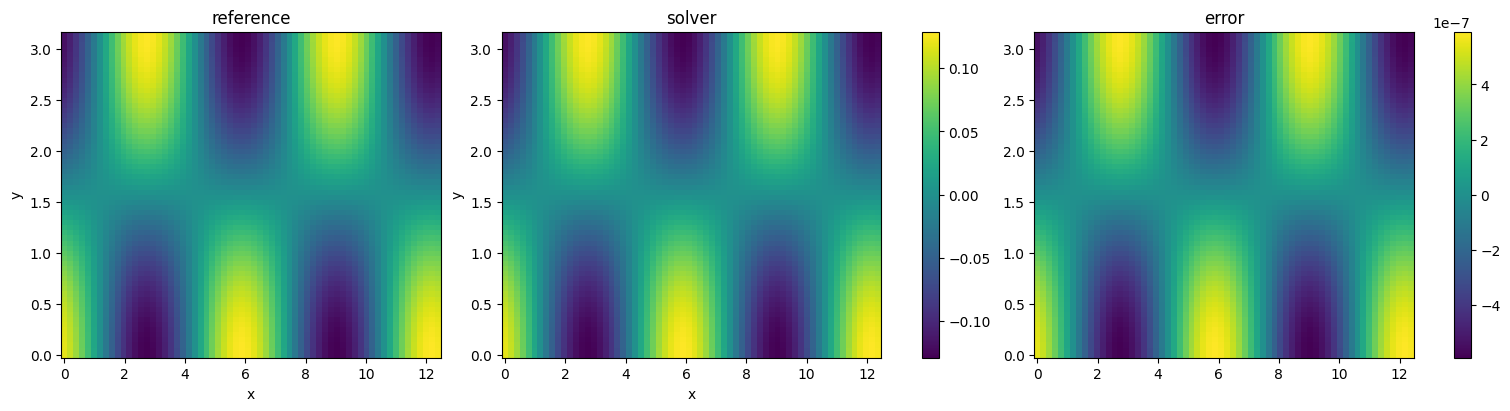

rel rmse: 4.58705421128967e-06


In [61]:
test_case1(collocated_pressure_modified_wavenumbers)

# Case 2: function with several modes
$ pressure = \sum_{q}A_q cos(w_{x,q} X + x_{phase}) * cos(w_{y,q} Y) * cos(w_{z,q} Z + z_{phase})$

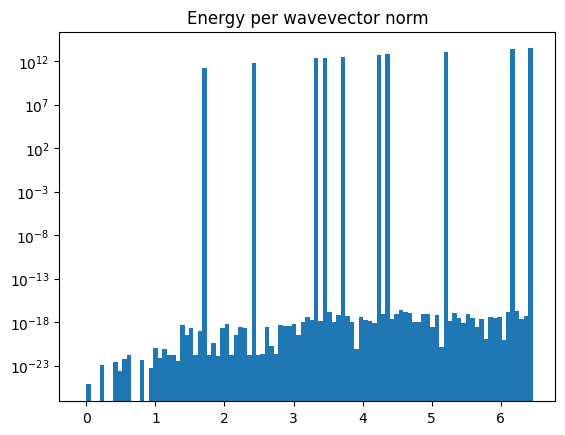

In [7]:
nx = 64
x_period = 2
Lx = 2*np.pi * x_period
ny = 64
Ly = np.pi
nz = 64
z_period = 5
Lz = 2*np.pi * z_period
x = np.linspace(0, Lx, nx, endpoint=False)
y = np.linspace(0, Ly, ny)
z = np.linspace(0, Lz, nz, endpoint=False)
x_phase = 0.4
z_phase = 1.7
X, Y, Z = np.ix_(x, y, z)
# Expected peaks: |k| = √(3n²), 1.73, 3.46, 5.20, ...
waves_freq = [[1, 1, 1], [2, 2, 2], [3, 3, 3], [2, 3, 1], [1, 3, 3], [1, 1, 2], [1, 3, 1], [4, 1, 1], [1, 6, 1], [2, 6, 1]]
p = np.zeros((nx, ny, nz))
rhs = np.zeros_like(p)
for wx, wy, wz in waves_freq:
    term = np.cos(wx * X + x_phase) * np.cos(wy * Y) * np.cos(wz * Z + z_phase)
    p += term
    rhs += -(wx**2 + wy**2 + wz**2) * term
dx = Lx / nx
dy = Ly / (ny - 1)
dz = Lz / nz
kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
ky = np.pi * np.arange(ny) / Ly
kz = 2 * np.pi * np.fft.fftfreq(nz, dz)
rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)
plot_energy_per_mode(rhshat, kx, ky, kz, 100)

In [62]:
# Harder func
def test_case2(solver):
    nx = 64
    x_period = 2
    Lx = 2*np.pi * x_period
    ny = 64
    Ly = np.pi
    nz = 64
    z_period = 5
    Lz = 2*np.pi * z_period
    x = np.linspace(0, Lx, nx, endpoint=False)
    y = np.linspace(0, Ly, ny)
    z = np.linspace(0, Lz, nz, endpoint=False)
    x_phase = 0.4
    z_phase = 1.7
    X, Y, Z = np.ix_(x, y, z)
    # Expected peaks: |k| = √(3n²), 1.73, 3.46, 5.20, ...
    waves_freq = [[1, 1, 1], [2, 2, 2], [3, 3, 3], [2, 3, 1], [1, 3, 3], [1, 1, 2], [1, 3, 1], [4, 1, 1], [1, 6, 1], [2, 6, 1]]
    p = np.zeros((nx, ny, nz))
    rhs = np.zeros_like(p)
    for wx, wy, wz in waves_freq:
        term = np.cos(wx * X + x_phase) * np.cos(wy * Y) * np.cos(wz * Z + z_phase)
        p += term
        rhs += -(wx**2 + wy**2 + wz**2) * term
    # run solver
    p_solver = solver(rhs, nx, ny, nz, Lx, Ly, Lz)
    p_ana = p - p.mean()
    p_num = p_solver.real - p_solver.real.mean()
    rel_rmse = np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))

    # plt visuals
    kslice = nz // 2
    ref = p_ana[:, :, kslice]
    num = p_num[:, :, kslice]
    
    vmin, vmax = ref.min(), ref.max()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    
    for a, f, t in zip(ax[:2], (ref, num), ("reference", "solver")):
        im = a.pcolormesh(x, y, f.T, vmin=vmin, vmax=vmax, shading="auto")
        a.set_title(t)
        a.set_xlabel("x"); a.set_ylabel("y")
    fig.colorbar(im, ax=ax[:2])
    
    err = ax[2].pcolormesh(x, y, (num - ref).T, shading="auto")
    ax[2].set_title("error")
    fig.colorbar(err, ax=ax[2])
    plt.show()
    print("rel rmse:", rel_rmse)

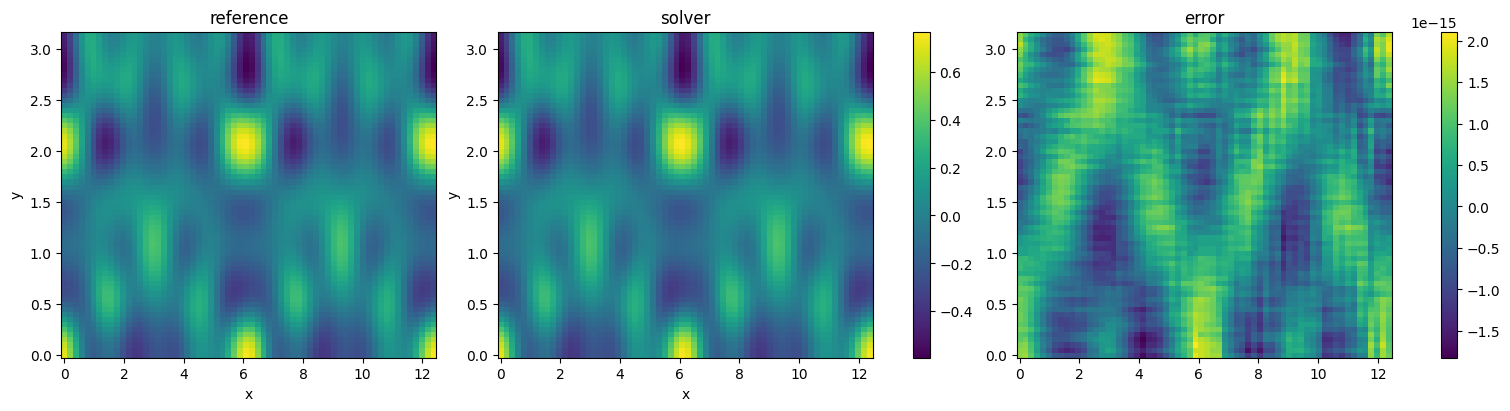

rel rmse: 1.6109351202121979e-15


In [35]:
test_case2(collocated_pressure_1)

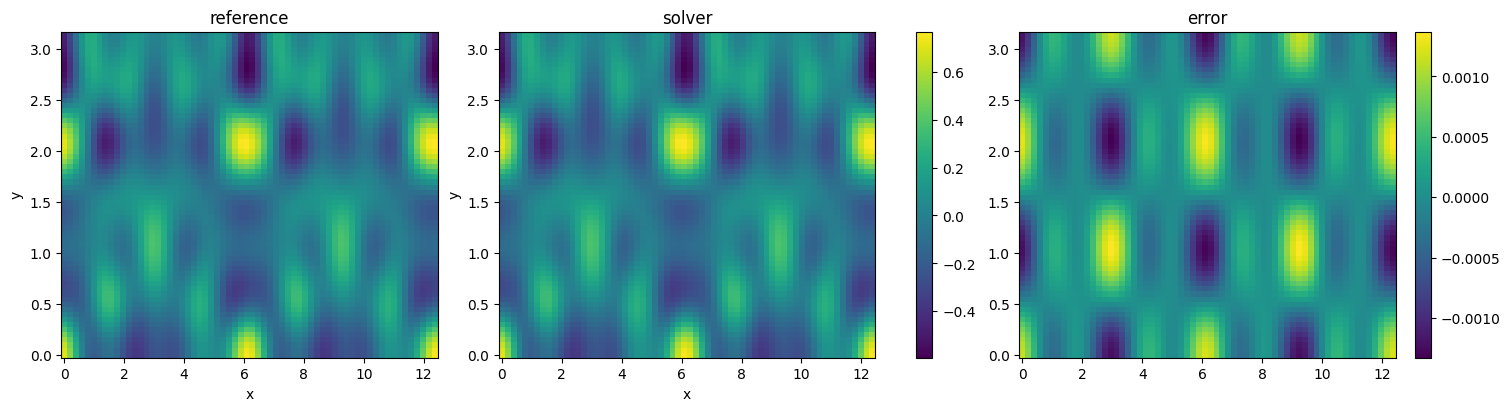

rel rmse: 0.0023349065376735145


In [63]:
test_case2(collocated_pressure_modified_wavenumbers)

# Case 3: More modes, uniform lx, lz



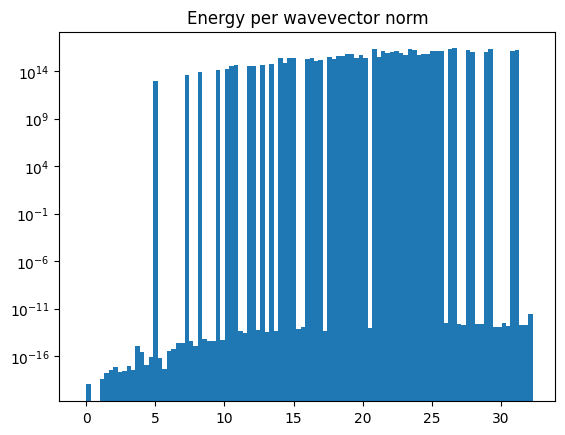

In [19]:
import random
res = 64
nx = res
x_period = 1
Lx = 2*np.pi * x_period
ny = res
Ly = np.pi
nz = res
z_period = 1
Lz = 2*np.pi * z_period
x = np.linspace(0, Lx, nx, endpoint=False)
y = np.linspace(0, Ly, ny)
z = np.linspace(0, Lz, nz, endpoint=False)
x_phase = 0.4
z_phase = 1.7
X, Y, Z = np.ix_(x, y, z)
# Expected peaks: |k| = √(3n²), 1.73, 3.46, 5.20, ...
peak_nb = 100
waves_freq = [[random.randint(1, 20), random.randint(1, 20), random.randint(1, 20)] for _ in range(peak_nb)]
p = np.zeros((nx, ny, nz))
rhs = np.zeros_like(p)
for wx, wy, wz in waves_freq:
    term = np.cos(wx * X + x_phase) * np.cos(wy * Y) * np.cos(wz * Z + z_phase)
    p += term
    rhs += -(wx**2 + wy**2 + wz**2) * term
dx = Lx / nx
dy = Ly / (ny - 1)
dz = Lz / nz
kx = 2 * np.pi * np.fft.fftfreq(nx, dx)
ky = np.pi * np.arange(ny) / Ly
kz = 2 * np.pi * np.fft.fftfreq(nz, dz)
rhsxzhat = np.fft.fftn(rhs, axes=(0, 2))
rhshat = scp.fft.dct(rhsxzhat, type=1, axis=1)
plot_energy_per_mode(rhshat, kx, ky, kz, 100)

In [20]:
# Harder func
def test_case3(solver):
    res = 64
    nx = res
    x_period = 1
    Lx = 2*np.pi * x_period
    ny = res
    Ly = np.pi
    nz = res
    z_period = 1
    Lz = 2*np.pi * z_period
    x = np.linspace(0, Lx, nx, endpoint=False)
    y = np.linspace(0, Ly, ny)
    z = np.linspace(0, Lz, nz, endpoint=False)
    x_phase = 0.4
    z_phase = 1.7
    X, Y, Z = np.ix_(x, y, z)
    # Expected peaks: |k| = √(3n²), 1.73, 3.46, 5.20, ...
    peak_nb = 100
    waves_freq = [[random.randint(1, 20), random.randint(1, 20), random.randint(1, 20)] for _ in range(peak_nb)]
    p = np.zeros((nx, ny, nz))
    rhs = np.zeros_like(p)
    for wx, wy, wz in waves_freq:
        term = np.cos(wx * X + x_phase) * np.cos(wy * Y) * np.cos(wz * Z + z_phase)
        p += term
        rhs += -(wx**2 + wy**2 + wz**2) * term
    # run solver
    p_solver = solver(rhs, nx, ny, nz, Lx, Ly, Lz)
    p_ana = p - p.mean()
    p_num = p_solver.real - p_solver.real.mean()
    rel_rmse = np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))

    # plt visuals
    kslice = nz // 2
    ref = p_ana[:, :, kslice]
    num = p_num[:, :, kslice]
    
    vmin, vmax = ref.min(), ref.max()
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    
    for a, f, t in zip(ax[:2], (ref, num), ("reference", "solver")):
        im = a.pcolormesh(x, y, f.T, vmin=vmin, vmax=vmax, shading="auto")
        a.set_title(t)
        a.set_xlabel("x"); a.set_ylabel("y")
    fig.colorbar(im, ax=ax[:2])
    
    err = ax[2].pcolormesh(x, y, (num - ref).T, shading="auto")
    ax[2].set_title("error")
    fig.colorbar(err, ax=ax[2])
    plt.show()
    print("rel rmse:", rel_rmse)

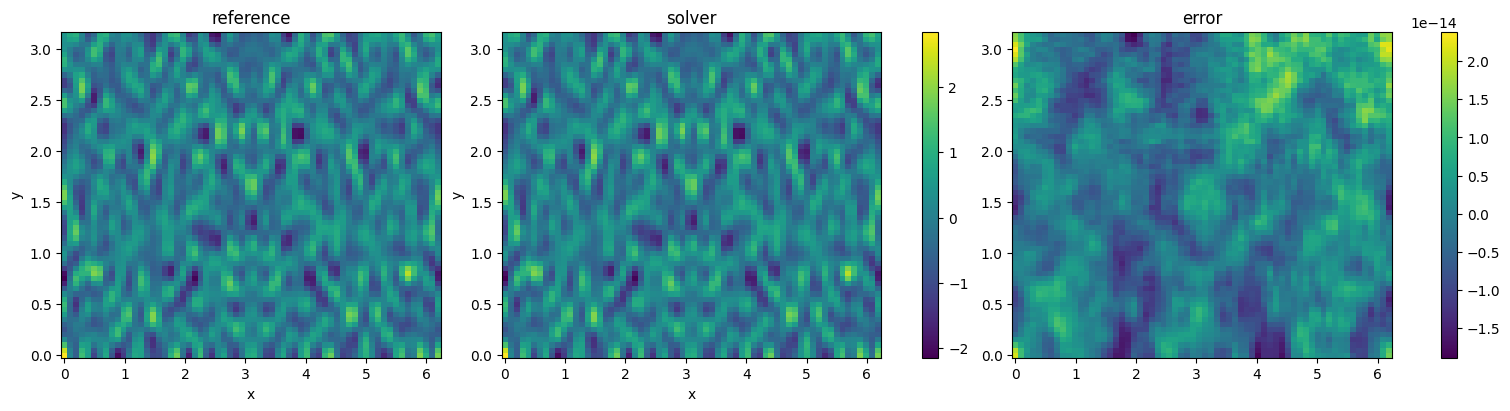

rel rmse: 4.962713359641922e-15


In [21]:
test_case3(collocated_pressure_1)

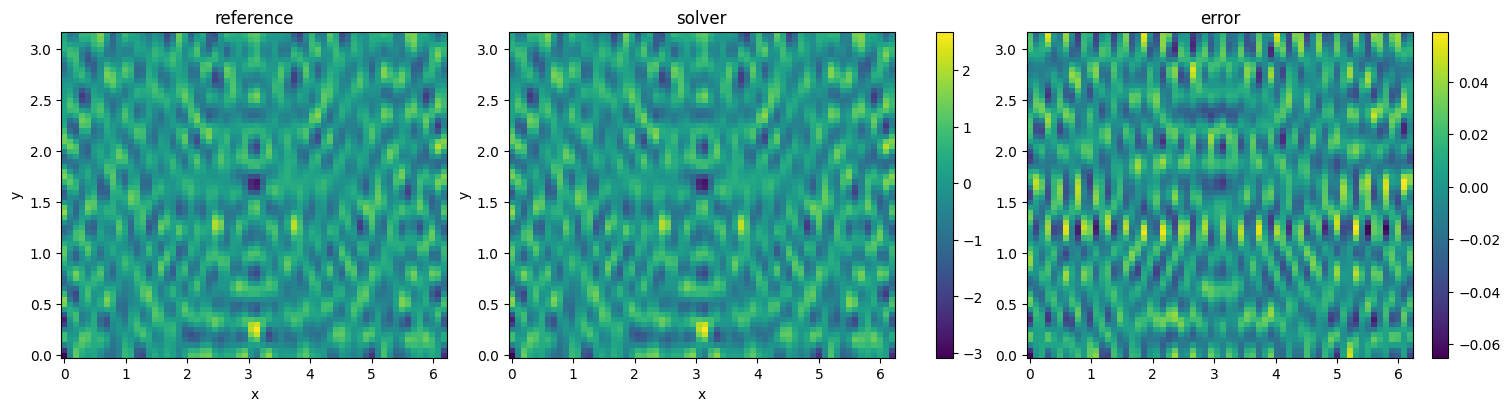

rel rmse: 0.029532505012335543


In [64]:
test_case3(collocated_pressure_modified_wavenumbers)

# Convergence test

In [58]:
import tqdm
def test_convergence(solver):
    resolutions = np.array([16, 32, 64, 128])
    errors = []
    
    for res in tqdm.tqdm(resolutions):
        nx = res
        x_period = 1
        Lx = 2*np.pi * x_period
        ny = res
        Ly = np.pi
        nz = res
        z_period = 1
        Lz = 2*np.pi * z_period
        x = np.linspace(0, Lx, nx, endpoint=False)
        y = np.linspace(0, Ly, ny)
        z = np.linspace(0, Lz, nz, endpoint=False)
        x_phase = 0.4
        z_phase = 1.7
        X, Y, Z = np.ix_(x, y, z)
        # Expected peaks: |k| = √(3n²), 1.73, 3.46, 5.20, ...
        peak_nb = 100
        waves_freq = [[random.randint(1, 5), random.randint(1, 5), random.randint(1, 5)] for _ in range(peak_nb)]
        p = np.zeros((nx, ny, nz))
        rhs = np.zeros_like(p)
        for wx, wy, wz in waves_freq:
            term = np.cos(wx * X + x_phase) * np.cos(wy * Y) * np.cos(wz * Z + z_phase)
            p += term
            rhs += -(wx**2 + wy**2 + wz**2) * term
    
        # run solver:
        p_solver = solver(rhs, nx, ny, nz, Lx, Ly, Lz)
        p_ana = p - p.mean()
        p_num = p_solver.real - p_solver.real.mean()
        rel_rmse = np.sqrt(np.mean((p_num - p_ana) ** 2)) / np.sqrt(np.mean(p_ana**2))
        errors.append(rel_rmse)
    errors = np.array(errors)
    h = Ly / (resolutions - 1)         # or any consistent measure, e.g. 1/N

    # observed order between consecutive resolutions
    orders = np.log(errors[:-1] / errors[1:]) / np.log(h[:-1] / h[1:])
    print(errors)
    print(orders)
    
    # fitted slope over all points
    slope = np.polyfit(np.log(h), np.log(errors), 1)[0]
    
    plt.loglog(h, errors, "o-", label=f"error (slope {slope:.2f})")
    plt.loglog(h, errors[0] * (h / h[0])**2, "k--", label="slope 2")
    plt.loglog(h, errors[0] * (h / h[0])**6, "k--", label="slope 6")
    plt.xlabel("h"); plt.ylabel("relative L2 error")
    plt.legend(); plt.grid(True, which="both", alpha=0.3)
    plt.show()


100%|██| 4/4 [00:02<00:00,  1.59it/s]


[2.36040250e-15 1.55074032e-15 1.41641721e-15 1.44979289e-15]
[ 0.57869996  0.12776163 -0.03322166]


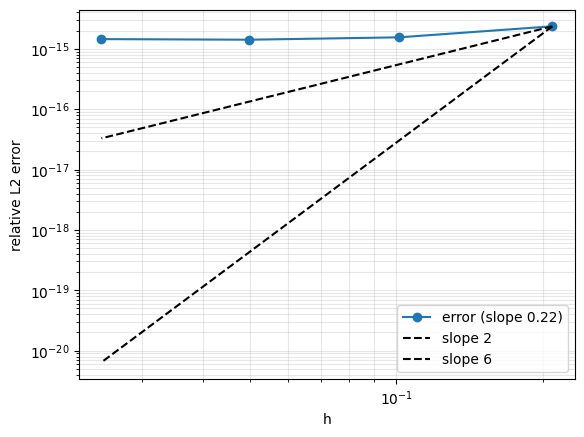

In [59]:
test_convergence(collocated_pressure_1)

100%|██| 4/4 [00:02<00:00,  1.87it/s]


[3.58475533e-02 3.86434987e-04 5.98187495e-06 9.34593880e-08]
[6.24030313 5.87780322 5.93245609]


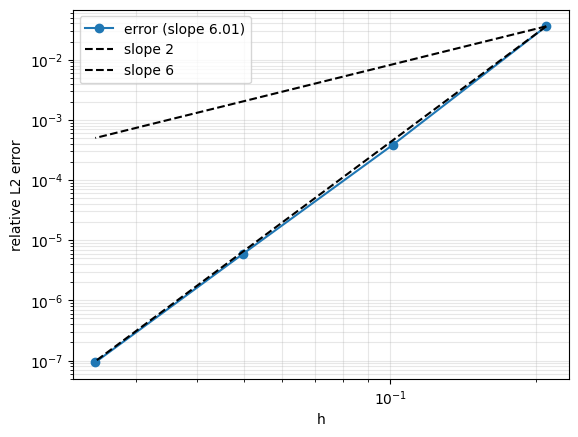

In [65]:
test_convergence(collocated_pressure_modified_wavenumbers)